# PDAN8412 – ICE Task 4
**Student Number:** SY10365068

## Preparing Images for an Image-Classification Project

The **PetImages** dataset (Microsoft Cats vs Dogs) is used. It contains two class folders, `Cat` and `Dog`. Before building a CNN, the images are:

1. Loaded into Python and their filenames displayed
2. Converted into NumPy arrays and their shapes inspected
3. Displayed in a grid using Matplotlib for visual inspection

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.utils import load_img, img_to_array

## Task 1: Upload and Load Images

First the available classes are checked and the number of files in each folder is counted (as done in the EDA notebook).

In [2]:
base_dir = "PetImages"

class_counts = {}
for class_name in sorted(os.listdir(base_dir)):
    class_path = os.path.join(base_dir, class_name)
    if os.path.isdir(class_path):
        class_counts[class_name] = len(os.listdir(class_path))

print("Classes found:", list(class_counts.keys()))
print(class_counts)

Classes found: ['Cat', 'Dog']
{'Cat': 12499, 'Dog': 12499}


Because the dataset contains roughly 25 000 images, a sample of **10 images per class** is loaded for this task. Only valid image files are loaded and any corrupt files are skipped using a `try/except` block (Pillow's `verify()`).

In [3]:
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")
images_per_class = 10

loaded_images = []   # list of (class_name, filename, PIL image)

for class_name in sorted(os.listdir(base_dir)):
    class_path = os.path.join(base_dir, class_name)
    if not os.path.isdir(class_path):
        continue

    count = 0
    for filename in sorted(os.listdir(class_path), key=lambda f: (len(f), f)):
        if count == images_per_class:
            break
        if not filename.lower().endswith(valid_extensions):
            continue

        file_path = os.path.join(class_path, filename)
        try:
            with Image.open(file_path) as img:
                img.verify()               # check the image is not corrupt
            image = load_img(file_path)    # load the image (RGB)
            loaded_images.append((class_name, filename, image))
            count += 1
        except Exception:
            print("Skipped corrupt file:", file_path)

print("Total images loaded:", len(loaded_images))

Total images loaded: 20


In [4]:
# Display the filenames of the loaded images
print("Filenames of the loaded images:\n")
for i, (class_name, filename, image) in enumerate(loaded_images, start=1):
    print(f"{i:2d}. {class_name}/{filename}")

Filenames of the loaded images:

 1. Cat/0.jpg
 2. Cat/1.jpg
 3. Cat/2.jpg
 4. Cat/3.jpg
 5. Cat/4.jpg
 6. Cat/5.jpg
 7. Cat/6.jpg
 8. Cat/7.jpg
 9. Cat/8.jpg
10. Cat/9.jpg
11. Dog/0.jpg
12. Dog/1.jpg
13. Dog/2.jpg
14. Dog/3.jpg
15. Dog/4.jpg
16. Dog/5.jpg
17. Dog/6.jpg
18. Dog/7.jpg
19. Dog/8.jpg
20. Dog/9.jpg


## Task 2: Convert Images to NumPy Arrays

Each image is converted into a NumPy array using `np.array()`. The shape and data type of every array are then displayed.

In [5]:
image_arrays = []

for class_name, filename, image in loaded_images:
    image_array = np.array(image)
    image_arrays.append(image_array)
    print(f"{class_name}/{filename:<10} -> shape: {image_array.shape}, dtype: {image_array.dtype}")

Cat/0.jpg      -> shape: (375, 500, 3), dtype: uint8
Cat/1.jpg      -> shape: (281, 300, 3), dtype: uint8
Cat/2.jpg      -> shape: (397, 312, 3), dtype: uint8
Cat/3.jpg      -> shape: (415, 500, 3), dtype: uint8
Cat/4.jpg      -> shape: (375, 500, 3), dtype: uint8
Cat/5.jpg      -> shape: (144, 176, 3), dtype: uint8
Cat/6.jpg      -> shape: (304, 400, 3), dtype: uint8
Cat/7.jpg      -> shape: (500, 495, 3), dtype: uint8
Cat/8.jpg      -> shape: (346, 461, 3), dtype: uint8
Cat/9.jpg      -> shape: (426, 320, 3), dtype: uint8
Dog/0.jpg      -> shape: (375, 500, 3), dtype: uint8
Dog/1.jpg      -> shape: (500, 327, 3), dtype: uint8
Dog/2.jpg      -> shape: (199, 188, 3), dtype: uint8
Dog/3.jpg      -> shape: (375, 500, 3), dtype: uint8
Dog/4.jpg      -> shape: (288, 300, 3), dtype: uint8
Dog/5.jpg      -> shape: (376, 500, 3), dtype: uint8
Dog/6.jpg      -> shape: (488, 500, 3), dtype: uint8
Dog/7.jpg      -> shape: (264, 300, 3), dtype: uint8
Dog/8.jpg      -> shape: (500, 470, 3), dtype:

In [6]:
# Inspect a single array in more detail
sample = image_arrays[0]
print("Shape:", sample.shape)
print("Height (rows):", sample.shape[0])
print("Width (columns):", sample.shape[1])
print("Channels:", sample.shape[2])
print("Min pixel value:", sample.min())
print("Max pixel value:", sample.max())
print("\nTop-left pixel [R, G, B]:", sample[0, 0])

Shape: (375, 500, 3)
Height (rows): 375
Width (columns): 500
Channels: 3
Min pixel value: 0
Max pixel value: 255

Top-left pixel [R, G, B]: [203 164  87]


In [7]:
# The Keras img_to_array function gives the same shape but stores the values as float32
keras_array = img_to_array(loaded_images[0][2])
print("np.array shape:     ", sample.shape, sample.dtype)
print("img_to_array shape: ", keras_array.shape, keras_array.dtype)

np.array shape:      (375, 500, 3) uint8
img_to_array shape:  (375, 500, 3) float32


### What the dimensions of the array represent

Each image becomes a **3-dimensional array** with the shape `(height, width, channels)`:

| Dimension | Meaning |
|---|---|
| **Height** (`shape[0]`) | The number of pixel **rows** in the image (vertical size) |
| **Width** (`shape[1]`) | The number of pixel **columns** in the image (horizontal size) |
| **Channels** (`shape[2]`) | The number of colour channels. `3` means the image is **RGB** (Red, Green, Blue) |

- Each element of the array is a pixel intensity between **0 and 255** (`uint8`). For example `image_array[0, 0]` returns the `[R, G, B]` values of the top-left pixel.
- The arrays have **different heights and widths** because the original photos are different sizes. Before training a CNN, all images must be **resized to the same dimensions** (e.g. `224 x 224`) and **normalised** (divided by 255 so values are between 0 and 1).
- When images are grouped into batches for a CNN, a fourth dimension is added at the front: `(batch_size, height, width, channels)`, e.g. `(32, 224, 224, 3)`.

In [8]:
# Demonstrate preparing one image for a CNN: resize, normalise and add a batch dimension
resized = np.array(loaded_images[0][2].resize((224, 224))) / 255.0
print("Resized + normalised shape:", resized.shape, "| range:", resized.min(), "-", round(resized.max(), 2))

batched = np.expand_dims(resized, axis=0)
print("With batch dimension:", batched.shape)

Resized + normalised shape: (224, 224, 3) | range: 0.0 - 1.0
With batch dimension: (1, 224, 224, 3)


## Task 3: Display the Images

10 images (5 cats and 5 dogs) are displayed in a 2 x 5 grid. Each title shows the class, filename and array shape. `plt.axis("off")` removes the axes so the images are clearly visible.

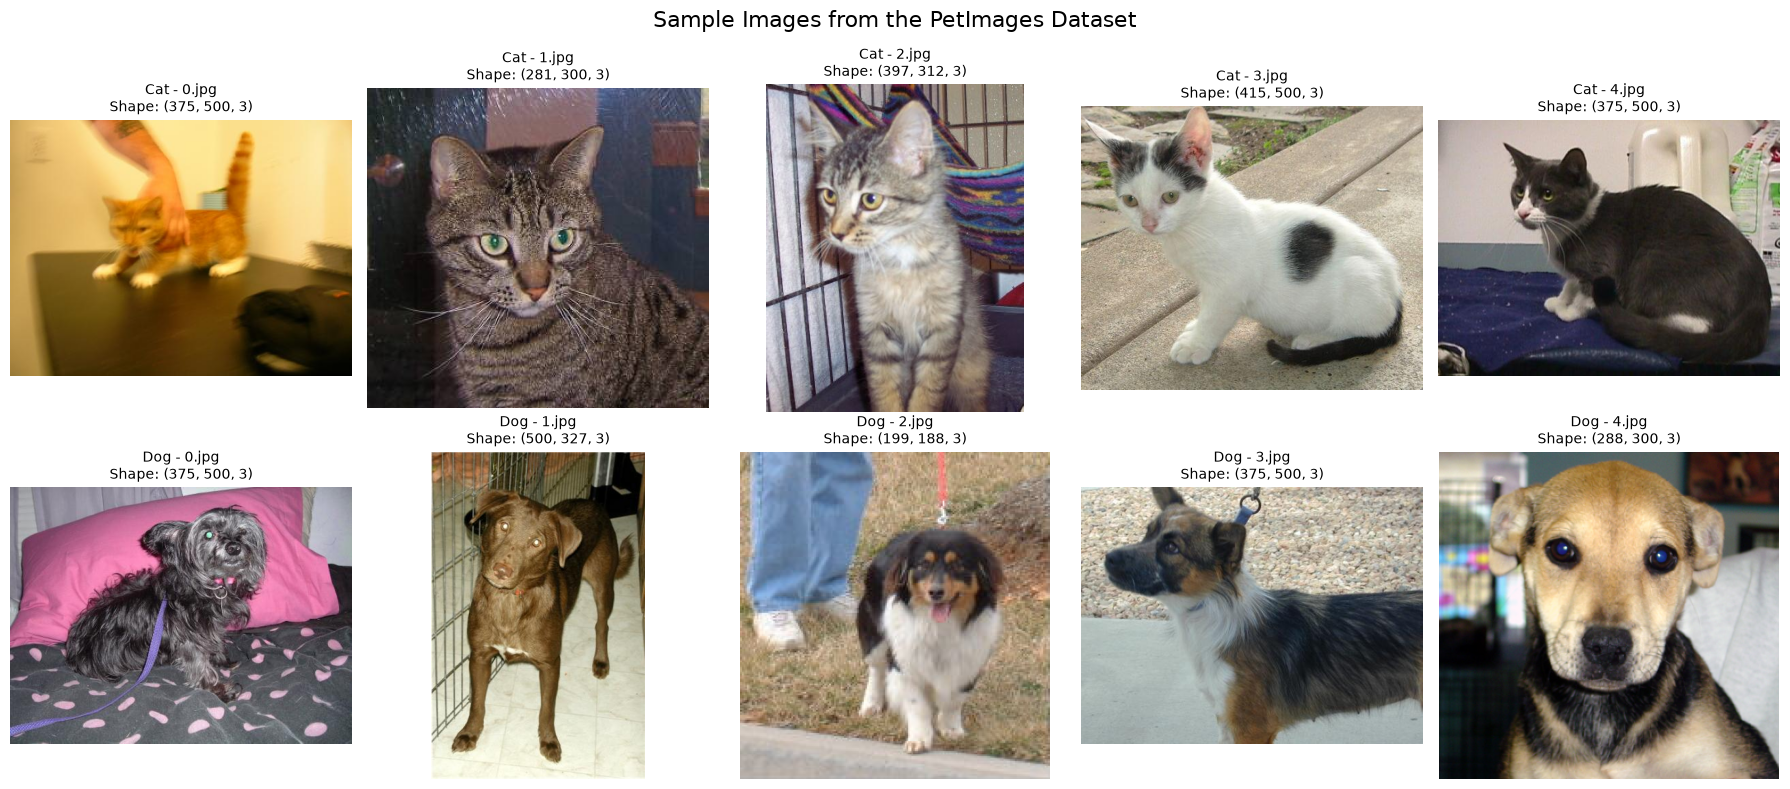

In [9]:
cats = [(n, f, img) for n, f, img in loaded_images if n == "Cat"][:5]
dogs = [(n, f, img) for n, f, img in loaded_images if n == "Dog"][:5]
display_images = cats + dogs

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for ax, (class_name, filename, image) in zip(axes, display_images):
    image_array = np.array(image)
    ax.imshow(image_array)
    ax.set_title(f"{class_name} - {filename}\nShape: {image_array.shape}", fontsize=10)
    ax.axis("off")

plt.suptitle("Sample Images from the PetImages Dataset", fontsize=16)
plt.tight_layout()
plt.show()

The same images can also be displayed after being resized to `224 x 224`, which shows what the CNN would receive as input once the images are standardised.

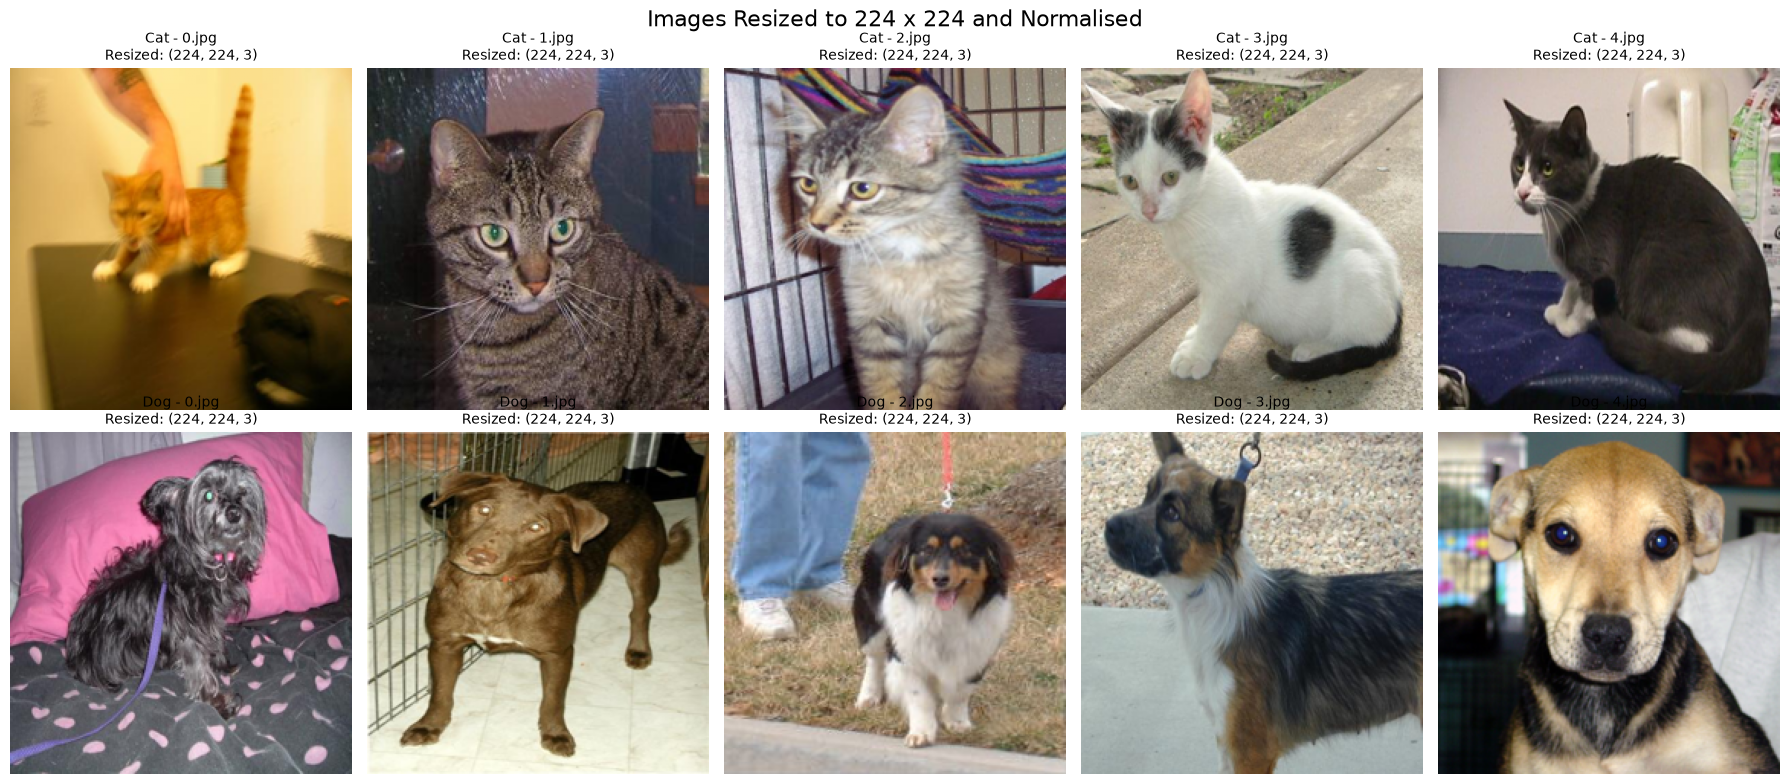

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for ax, (class_name, filename, image) in zip(axes, display_images):
    resized_array = np.array(image.resize((224, 224))) / 255.0
    ax.imshow(resized_array)
    ax.set_title(f"{class_name} - {filename}\nResized: {resized_array.shape}", fontsize=10)
    ax.axis("off")

plt.suptitle("Images Resized to 224 x 224 and Normalised", fontsize=16)
plt.tight_layout()
plt.show()

## Conclusion

- The images were loaded from the `PetImages` folder (classes `Cat` and `Dog`) and their filenames displayed.
- Each image was converted into a NumPy array of shape **(height, width, 3)** where the dimensions are rows of pixels, columns of pixels and the RGB colour channels, with values from 0–255.
- The image sizes vary, so resizing (e.g. to 224 x 224) and normalising (dividing by 255) are required before training a CNN.
- The images were displayed in a labelled grid using Matplotlib to confirm they loaded correctly.